# 03 · GPT 组装：Block、残差、权重共享

**Source audit:** [karpathy/nanoGPT](https://github.com/karpathy/nanoGPT/tree/3adf61e154c3fe3fca428ad6bc3818b27a3b8291) at `3adf61e154c3`; relevant files: `model.py`, `train.py`, `sample.py`, `data/shakespeare_char/prepare.py`, `config/train_shakespeare_char.py`.

**Scope:** The notebook uses a small **educational adaptation** (`nanogpt_edu.py`) consistent with the original architecture, not a verbatim copy of the full upstream training program. No pretrained weights, external datasets, downloads, distributed GPUs, or performance reproduction are claimed. Figures and prints are generated by real local CPU executions. The project's README has marked nanoGPT deprecated since Nov 2025 and points to nanochat.

## 从 Block 组装 decoder-only GPT

对应 `model.py/Block`, `GPTConfig`, `GPT.forward`。流程：token embedding + position embedding → (LayerNorm→Attention→Residual, LayerNorm→MLP→Residual)×L → Final LN → LM Head。训练时 logits 覆盖整个序列；仅采样时只计算最后位置的 logits。

In [1]:
from pathlib import Path
import sys, torch, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
# Compatible with starting Jupyter from the notebook directory OR repository root.
P = Path.cwd().resolve()
ROOT = P if (P / 'nanogpt_edu.py').exists() else P.parent
if not (ROOT / 'nanogpt_edu.py').exists():
    raise RuntimeError('Open this notebook from tutorials/nanogpt/notebooks or the tutorials/nanogpt directory')
sys.path.insert(0, str(ROOT))
from nanogpt_edu import GPTConfig, GPT, char_dataset, get_batch, training_text, lr_schedule, parameter_groups
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(min(2, torch.get_num_threads()))
torch.manual_seed(42); np.random.seed(42)
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| CPU tutorial', '| path:', ROOT)

Python: 3.13.5 | PyTorch: 2.10.0+cpu | CPU tutorial | path: /mnt/notebook-builder/tutorials/nanogpt


Config: GPTConfig(vocab_size=27, block_size=24, n_layer=2, n_head=2, n_embd=32, dropout=0.0, bias=True)
Block: Block(
  (ln_1): LayerNorm()
  (attn): CausalSelfAttention(
    (c_attn): Linear(in_features=32, out_features=96, bias=True)
    (c_proj): Linear(in_features=32, out_features=32, bias=True)
    (resid_dropout): Dropout(p=0.0, inplace=False)
  )
  (ln_2): LayerNorm()
  (mlp): MLP(
    (c_fc): Linear(in_features=32, out_features=128, bias=True)
    (gelu): GELU(approximate='none')
    (c_proj): Linear(in_features=128, out_features=32, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
)
Embedding and LM head share the SAME underlying weights: True
Total unique parameters: 27104
Parameter groups: {'Embedding + LM head': 864, 'Position Embedding': 768, 'Attention': 8448, 'MLP': 16704, 'LayerNorm': 320}


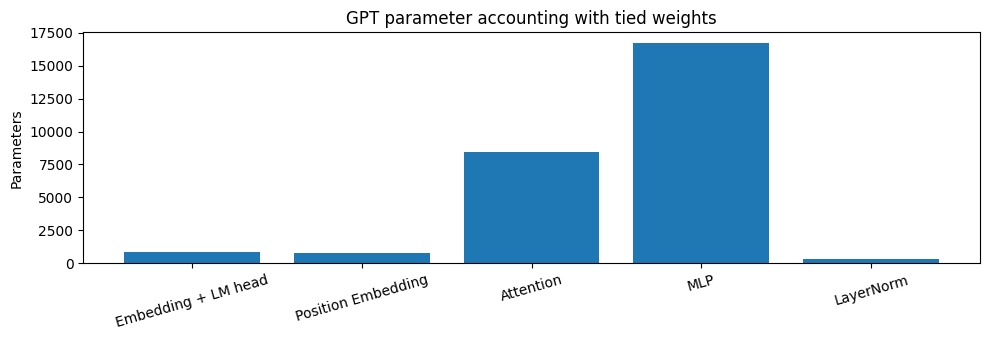

In [2]:
ids, stoi, itos=char_dataset(training_text(repeats=12))
cfg=GPTConfig(vocab_size=len(stoi),block_size=24,n_layer=2,n_head=2,n_embd=32)
model=GPT(cfg)
shared = model.transformer.wte.weight.data_ptr() == model.lm_head.weight.data_ptr()
print('Config:',cfg); print('Block:',model.transformer.h[0])
print('Embedding and LM head share the SAME underlying weights:',shared)
print('Total unique parameters:',sum(p.numel() for p in model.parameters()))
assert shared
names=['Embedding + LM head','Position Embedding','Attention','MLP','LayerNorm']
vals=[model.transformer.wte.weight.numel(),model.transformer.wpe.weight.numel(),
 sum(p.numel() for b in model.transformer.h for p in b.attn.parameters()),
 sum(p.numel() for b in model.transformer.h for p in b.mlp.parameters()),
 sum(p.numel() for b in model.transformer.h for part in (b.ln_1,b.ln_2) for p in part.parameters())+sum(p.numel() for p in model.transformer.ln_f.parameters())]
print('Parameter groups:',dict(zip(names,vals)))
assert sum(vals)==sum(p.numel() for p in model.parameters())
fig,ax=plt.subplots(figsize=(10,3.5));ax.bar(names,vals);ax.tick_params(axis='x',labelrotation=16);ax.set_ylabel('Parameters');ax.set_title('GPT parameter accounting with tied weights');fig.tight_layout()
fig.savefig(FIG/'03_model_parameters.png',dpi=130);display(fig);plt.close(fig)

Batch X: (4, 24) Target Y: (4, 24) Logits: (4, 24, 27)
Cross entropy (untrained): 3.3142
Gradient norm examples: [('transformer.wte.weight', 0.86267), ('transformer.wpe.weight', 0.46048), ('transformer.h.0.ln_1.weight', 0.00147), ('transformer.h.0.ln_1.bias', 0.00644), ('transformer.h.0.attn.c_attn.weight', 0.10978)]


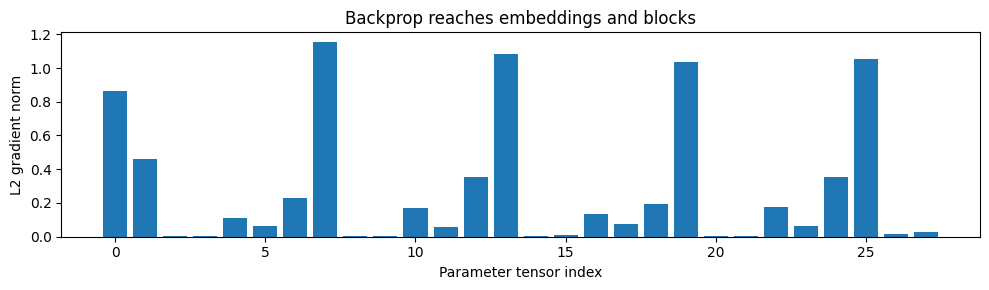

In [3]:
x,y=get_batch(ids,cfg.block_size,batch_size=4,generator=torch.Generator().manual_seed(11))
logits,loss=model(x,y)
print('Batch X:',tuple(x.shape),'Target Y:',tuple(y.shape),'Logits:',tuple(logits.shape))
print('Cross entropy (untrained):',round(loss.item(),4))
loss.backward()
grad_by_layer=[(name, p.grad.norm().item()) for name,p in model.named_parameters() if p.grad is not None]
print('Gradient norm examples:',[(k,round(v,5)) for k,v in grad_by_layer[:5]])
assert torch.isfinite(loss) and all(np.isfinite(v) for _,v in grad_by_layer)
fig,ax=plt.subplots(figsize=(10,3));ax.bar(range(len(grad_by_layer)),[v for _,v in grad_by_layer]);ax.set_ylabel('L2 gradient norm');ax.set_xlabel('Parameter tensor index');ax.set_title('Backprop reaches embeddings and blocks');fig.tight_layout()
fig.savefig(FIG/'03_gradient_norms.png',dpi=130);display(fig);plt.close(fig)

### 小测验

若 `n_embd=32`、`n_head=2`，每个 head 的维度是多少？移除权重共享会新增多少参数？思考 residual connection 为何能改善多层网络的优化。